### Imports

In [173]:
!pip install --upgrade jupyter
!pip install --upgrade ipywidgets

In [5]:
"""
This is a basic example of what you need to do to enter the crunch.
The code will not have access to the internet (or any socket related operation).
"""

#!pip install matplotlib

import networkx as nx
import matplotlib.pyplot as plt


import functools
import os
import typing

import joblib
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, ttest_rel
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_regression
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm  # type: ignore

In [11]:
import pickle

# Replace 'filename.pkl' with your pickle file's name
with open('data/X_train.pickle', 'rb') as file:
    X_train = pickle.load(file)

with open('data/y_train.pickle', 'rb') as file:
    y_train = pickle.load(file)    

with open('data/X_test.pickle', 'rb') as file:
    X_test = pickle.load(file)

with open('data/y_test.pickle', 'rb') as file:
    y_test = pickle.load(file)

names_graphs_train = y_train

## Useful Functions

The following functions are provided to help you get the class labels of the variables in a graph according to their relationship to `X` and `Y`. The variables can be colliders, confounders, mediators, etc.

This is the core of the solution code, which reads one record at a time, applies the PC algorithm, ensures that the result is a DAG, and then puts the result into a single data frame in the required format, ready for submission.

In [3]:
def graph_nodes_representation(graph, nodelist):
    """
    Create an alternative representation of a graph which is hashable
    and equivalent graphs have the same hash.

    Python cannot PROPERLY use nx.Graph/DiGraph as key for
    dictionaries, because two equivalent graphs with just different
    order of the nodes would result in different keys. This is
    undesirable here.

    So here we transform the graph into an equivalent form that is
    based on a specific nodelist and that is hashable. In this way,
    two equivalent graphs, once transformed, will result in identical
    keys.

    So we use the following trick: extract the adjacency matrix
    (with nodes in a fixed order) and then make a hashable thing out
    of it, through tuple(array.flatten()):
    """

    # This get the adjacency matrix with nodes in a given order, as
    # numpy array (which is not hashable):
    adjacency_matrix = nx.adjacency_matrix(graph, nodelist=nodelist).todense()

    # This transforms the numpy array into a hashable object:
    hashable = tuple(adjacency_matrix.flatten())

    return hashable

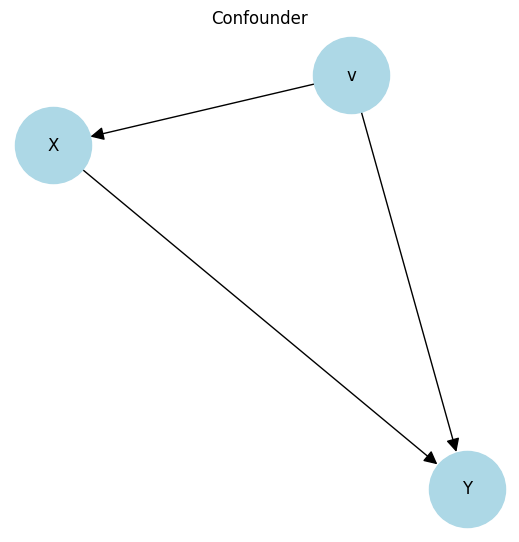

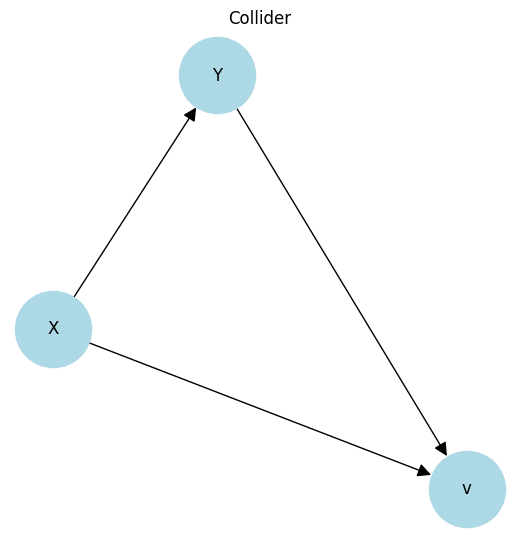

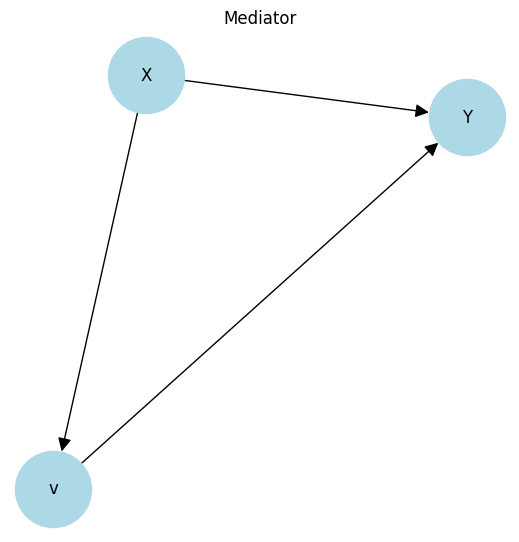

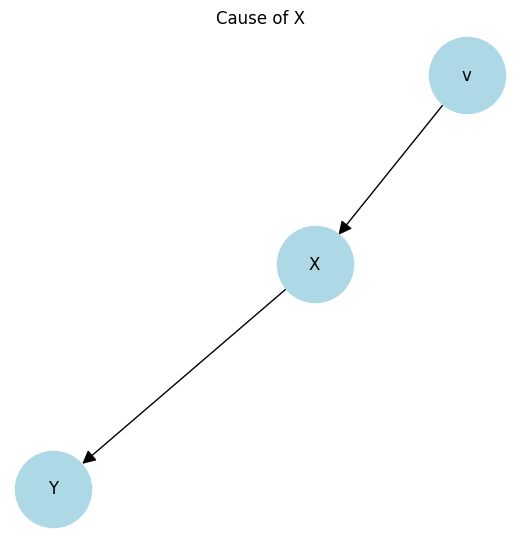

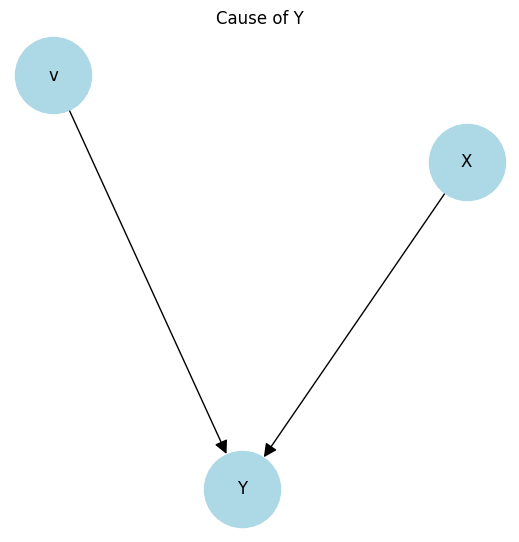

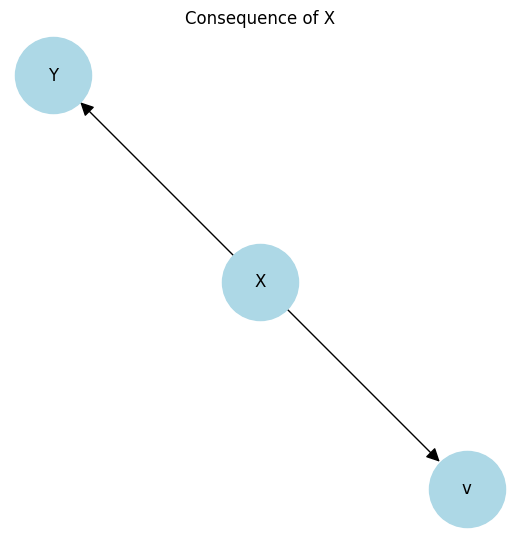

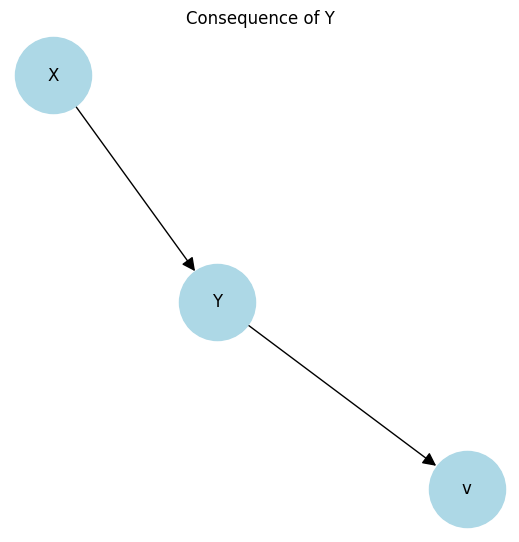

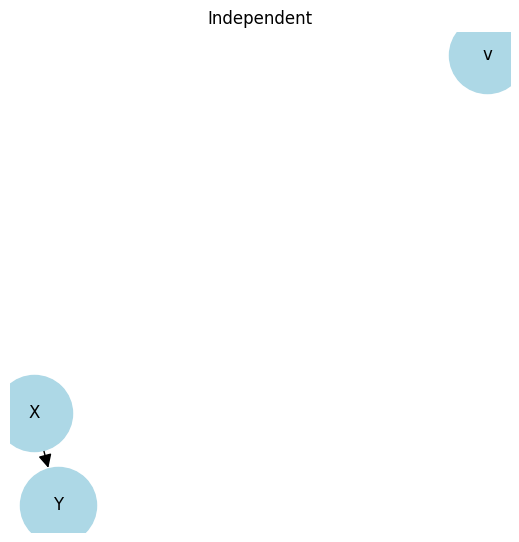

In [22]:
import networkx as nx
import matplotlib.pyplot as plt

graph_label = {
    nx.DiGraph([("X", "Y"), ("v", "X"), ("v", "Y")]): "Confounder",
    nx.DiGraph([("X", "Y"), ("X", "v"), ("Y", "v")]): "Collider",
    nx.DiGraph([("X", "Y"), ("X", "v"), ("v", "Y")]): "Mediator",
    nx.DiGraph([("X", "Y"), ("v", "X")]):             "Cause of X",
    nx.DiGraph([("X", "Y"), ("v", "Y")]):             "Cause of Y",
    nx.DiGraph([("X", "Y"), ("X", "v")]):             "Consequence of X",
    nx.DiGraph([("X", "Y"), ("Y", "v")]):             "Consequence of Y",
    nx.DiGraph({"X": ["Y"], "v": []}):                "Independent",
}

nodelist = ["v", "X", "Y"]

# Plot each graph
for graph, label in graph_label.items():
    plt.figure(figsize=(5, 5))
    pos = nx.spring_layout(graph)  # You can use different layouts like spring_layout, circular_layout, etc.
    nx.draw(graph, pos, with_labels=True, node_size=3000, node_color="lightblue", arrowsize=20)
    plt.title(label)
    plt.show()

In [13]:
def create_graph_label():
    """
    Create a dictionary from graphs to labels, in two formats.
    """
    graph_label = {
        nx.DiGraph([("X", "Y"), ("v", "X"), ("v", "Y")]): "Confounder",
        nx.DiGraph([("X", "Y"), ("X", "v"), ("Y", "v")]): "Collider",
        nx.DiGraph([("X", "Y"), ("X", "v"), ("v", "Y")]): "Mediator",
        nx.DiGraph([("X", "Y"), ("v", "X")]):             "Cause of X",
        nx.DiGraph([("X", "Y"), ("v", "Y")]):             "Cause of Y",
        nx.DiGraph([("X", "Y"), ("X", "v")]):             "Consequence of X",
        nx.DiGraph([("X", "Y"), ("Y", "v")]):             "Consequence of Y",
        nx.DiGraph({"X": ["Y"], "v": []}):                "Independent",
    }

    nodelist = ["v", "X", "Y"]

    # This is an equivalent alternative to graph_label but in a form
    # for which two equivalent graphs have the same key:
    adjacency_label = {
        graph_nodes_representation(graph, nodelist): label
        for graph, label in graph_label.items()
    }

    return graph_label, adjacency_label

In [14]:
def get_labels(adjacency_matrix, adjacency_label):
    """
    Transform an adjacency_matrix (as pd.DataFrame) into a dictionary of variable:label
    """

    result = {}
    for variable in adjacency_matrix.columns.drop(["X", "Y"]):
        submatrix = adjacency_matrix.loc[[variable, "X", "Y"], [variable, "X", "Y"]]  # this is not hashable
        key = tuple(submatrix.values.flatten())  # this is hashable and a compatible with adjacency_label

        result[variable] = adjacency_label[key]

    return result

In [21]:
def get_adjacency_matrix_from_labels(variable_labels, adjacency_label):
    """
    Given a dictionary of variable:label mappings, this function will attempt
    to reverse the process and reconstruct the adjacency matrix (as pd.DataFrame)
    that corresponds to those labels.

    Parameters:
    variable_labels (dict): A dictionary where keys are variables and values are labels.
    adjacency_label (dict): A dictionary mapping from adjacency matrix representations (in hashable form) to labels.

    Returns:
    pd.DataFrame: The reconstructed adjacency matrix.
    """

    # Initialize an empty adjacency matrix as a pandas DataFrame
    variables = list(variable_labels.keys()) + ["X", "Y"]
    adjacency_matrix = pd.DataFrame(0, index=variables, columns=variables)

    # Reverse lookup: Find adjacency structure based on labels
    label_to_adjacency = {v: k for k, v in adjacency_label.items()}  # Reverse the adjacency_label dictionary

    for variable, label in variable_labels.items():
        if label in label_to_adjacency:
            # Retrieve the adjacency pattern (hashable) based on the label
            adjacency_pattern = label_to_adjacency[label]
            # Convert the pattern back into a submatrix and update the adjacency matrix
            adjacency_submatrix = np.array(adjacency_pattern).reshape(3, 3)
            adjacency_matrix.loc[[variable, "X", "Y"], [variable, "X", "Y"]] = adjacency_submatrix
        else:
            raise ValueError(f"Label '{label}' not found in adjacency_label.")

    return adjacency_matrix

variable_labels = {
    "v": "Confounder",
}

test_fun = False
if test_fun == True:
    # Example adjacency_label (from create_graph_label)
    _, adjacency_label = create_graph_label()

    # Recreate the adjacency matrix from the variable-label mappings
    adjacency_matrix = get_adjacency_matrix_from_labels(variable_labels, adjacency_label)
    print(adjacency_matrix)

    A = y_train['01909']
    A = A.sort_index(axis=0).sort_index(axis=1)
    display(A)
    A_labels = pd.Series(get_labels(A, adjacency_label), name="label").rename_axis("variable")
    display(A_labels)
    print("**********")
    A_prime = get_adjacency_matrix_from_labels(A_labels, adjacency_label)
    display(A_prime)
    A_prime_labels = pd.Series(get_labels(A, adjacency_label), name="label").rename_axis("variable")
    display(A_prime_labels)


   v  X  Y
v  0  1  1
X  0  0  1
Y  0  0  0


,0,1,2,3,4,5,7,9,X,Y
parent,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,1
5,0,1,1,1,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0
9,1,0,0,1,0,0,0,0,0,0
X,0,0,0,0,0,0,0,0,0,1


variable
0    Independent
1     Cause of Y
2    Independent
3    Independent
4     Cause of Y
5    Independent
7    Independent
9    Independent
Name: label, dtype: object

**********


,0,1,2,3,4,5,7,9,X,Y
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,1
5,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0
X,0,0,0,0,0,0,0,0,0,1
Y,0,0,0,0,0,0,0,0,0,0


variable
0    Independent
1     Cause of Y
2    Independent
3    Independent
4     Cause of Y
5    Independent
7    Independent
9    Independent
Name: label, dtype: object

Example 1: manually creating the adjacency matrix.

In [24]:
graph_label, adjacency_label = create_graph_label()

,0,1,X,Y
parent,,,,
0,0,0,1,0
1,0,0,0,0
X,0,1,0,1
Y,0,1,0,0


{'0': 'Cause of X', '1': 'Collider'}


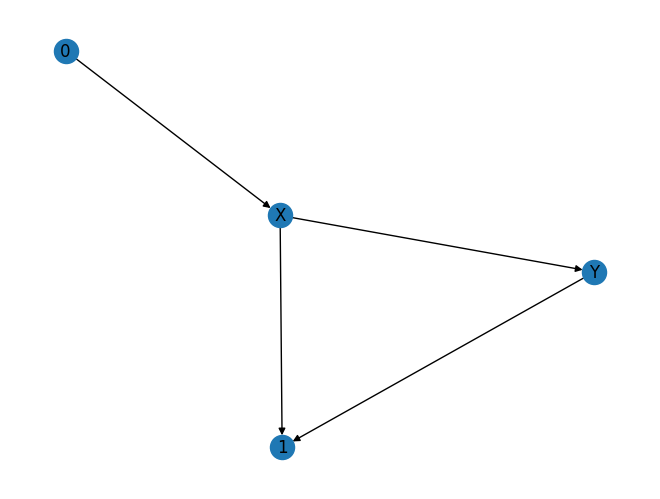

In [25]:
A = pd.DataFrame(
    data = {
        "0": [0, 0, 1, 0],
        "1": [0, 0, 0, 0],
        "X": [0, 1, 0, 1],
        "Y": [0, 1, 0, 0],
    },
    index = ["0", "1", "X", "Y"]
).T
A.index.name = "parent"
display(A)

g = nx.DiGraph(A)
nx.draw(g, with_labels=True)
print(get_labels(A, adjacency_label))

Example 2: loading an adjacency matrix from the training set.

,0,1,2,3,4,5,Y,7,X,9
parent,,,,,,,,,,
0,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0
5,0,1,1,1,0,0,0,0,0,0
Y,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,0,0
X,0,0,0,0,0,0,1,0,0,0


variable
0    Independent
1     Cause of Y
2    Independent
3    Independent
4     Cause of Y
5    Independent
7    Independent
9    Independent
Name: label, dtype: object

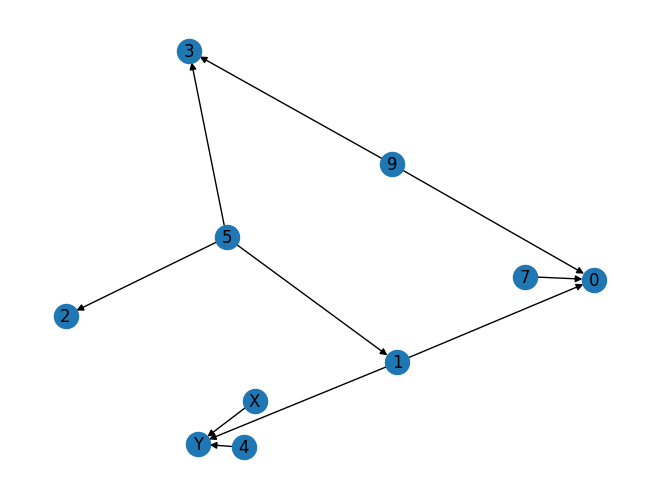

In [27]:
names_graphs_train = y_train
A = names_graphs_train['01909'] #['00016']
display(A)

g = nx.DiGraph(A)
nx.draw(g, with_labels=True)
display(pd.Series(get_labels(A, adjacency_label), name="label").rename_axis("variable"))

## Variable embedding

The following functions compute features for each variable in a dataset according to its relationship to the other variables, and specifically to `X` and `Y`. The features are divided into three groups:
- Based on the Pearson's correlation coefficient between variables.
- Based on the $t$ test.
- Based on mutual information.

Using the same API and the `get_label()` function above, we can also get labels for each variable.

In [6]:
def pearson_correlation(dataset):
    """
    Given a dataset, we compute the correlation-based features for each
    varibale, which are the correlation between that variable with X and Y,
    as well as summary statistics (max, min, mean, std) of all pairs
    of correlations.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        tmp = dataset.corr().drop([variable], axis="columns").loc[variable].abs()

        df.append({
            "variable": variable,
            "corr(v,X)": dataset[[variable, "X"]].corr().loc[variable, "X"],
            "corr(v,Y)": dataset[[variable, "Y"]].corr().loc[variable, "Y"],
            "max(corr(v, others))": tmp.max(),
            "min(corr(v, others))": tmp.min(),
            "mean(corr(v, others))": tmp.mean(),
            "std(corr(v, others))": tmp.std(),
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    df["corr(X,Y)"] = dataset[["X", "Y"]].corr().loc["X", "Y"]

    # pearsonr is NaN when the variance is 0, so we fill with 0
    df.fillna(0, inplace=True)

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [7]:
def ttest(dataset, pvalue_threshold=0.05):
    """
    Given a dataset, this function computes the t-test between the
    values each variable v and X, Y. The t value and the result of the
    t-test with a given pvalue_threshold, are used to create features
    to describe/embed v, as well as the t-test result between the
    values of X and Y.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        ttest_vX = ttest_rel(dataset[variable], dataset["X"])
        ttest_vY = ttest_rel(dataset[variable], dataset["Y"])

        df.append({
            "variable": variable,
            "ttest(v,X)": ttest_vX.statistic,
            f"pvalue(ttest(v,X))<={pvalue_threshold}": (ttest_vX.pvalue <= pvalue_threshold).astype(float),
            "ttest(v,Y)": ttest_vY.statistic,
            f"pvalue(ttest(v,Y))<={pvalue_threshold}": (ttest_vY.pvalue <= pvalue_threshold).astype(float),
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    ttest_XY = ttest_rel(dataset["X"], dataset["Y"])
    df["ttest(X,Y)"] = ttest_XY.statistic
    df[f"pvalue(ttest(X,Y))<={pvalue_threshold}"] = (ttest_XY.pvalue <= pvalue_threshold).astype(float)

    # some the ttest returns NaN when the variance is 0, so we fill with 0:
    df.fillna(0, inplace=True)

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [8]:
def mutual_information(dataset):
    """
    Given a dataset, we compute the mutual-information-based features
    for each varibale, which are the correlation between that variable
    X and Y, as well as summary statistics (max, min, mean, std) of
    all pairs of correlations.
    """

    variables = dataset.columns.drop(["X", "Y"])

    df = []
    for variable in variables:
        tmp = mutual_info_regression(dataset.drop(columns=[variable]), dataset[variable])

        df.append({
            "variable": variable,
            "MI(v,X)": mutual_info_regression(dataset[[variable]], dataset["X"], discrete_features=False)[0],
            "MI(v,Y)": mutual_info_regression(dataset[[variable]], dataset["Y"], discrete_features=False)[0],
            "max(MI(v, others))": tmp.max(),
            "min(MI(v, others))": tmp.min(),
            "mean(MI(v, others))": tmp.mean(),
            "std(MI(v, others))": tmp.std(),
        })

    df = pd.DataFrame(df)
    df["dataset"] = dataset.name

    df["MI(X,Y)"] = mutual_info_regression(dataset[["X"]], dataset["Y"], discrete_features=False)[0]

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

In [37]:
def label(adjacency_matrix):
    """
    Given a graph as adjacency_matrix, create the class labels of each variable.
    """

    adjacency_graph, adjacency_label = create_graph_label()
    labels = get_labels(adjacency_matrix, adjacency_label)
    variables = adjacency_matrix.columns.drop(["X", "Y"])

    df = pd.DataFrame({
        "variable": variables,
        "label": [labels[variable] for variable in variables],
    })
    df["dataset"] = adjacency_matrix.name

    # Reorder columns:
    df = df[["dataset"] + [colname for colname in df.columns if colname != "dataset"]]

    return df

Example: loading a dataset from the training set and creating a feature embedding for its variables, as well as class labels:

In [39]:
names_datasets_train = X_train

name = "00016"
dataset = names_datasets_train[name]
dataset.name = name
X_dataset = pearson_correlation(dataset)

print("X_dataset:")
display(X_dataset)

print(len(names_datasets_train))
print("y_dataset:")
adjacency_matrix = names_graphs_train[name]
adjacency_matrix.name = name
y_dataset = label(adjacency_matrix=adjacency_matrix)
display(y_dataset)

X_dataset:


,dataset,variable,"corr(v,X)","corr(v,Y)","max(corr(v, others))","min(corr(v, others))","mean(corr(v, others))","std(corr(v, others))","corr(X,Y)"
0,00016,0,0.364560,0.566518,0.566518,0.057363,0.266090,0.203312,0.102592
1,00016,1,0.299588,-0.361272,0.361272,0.012459,0.225776,0.149439,0.102592
2,00016,2,-0.025934,0.310212,0.310212,0.012459,0.085635,0.126666,0.102592
3,00016,4,-0.906602,-0.137594,0.906602,0.022204,0.321691,0.345429,0.102592


23500
y_dataset:


,dataset,variable,label
0,00016,0,Collider
1,00016,1,Cause of Y
2,00016,2,Cause of Y
3,00016,4,Confounder


## Computing `(X_train, y_train)`

The following functions loop over a list of given dataset names and execute the desired variable embeddings defined previously to create a single `(X_train, y_train)` suitable for a multiclass classification problem.

In [41]:
def create_some_columns(names_datasets, function):
    """
    Apply an embedding function to a list of datasets.
    """

    df = []
    for name, dataset in tqdm(names_datasets.items()):
        dataset = names_datasets[name]
        dataset.name = name

        try:
            df_dataset = function(dataset)
        except ValueError as e:
            print(name, e)
            raise NotImplementedError

        df_dataset["dataset"] = name
        df.append(df_dataset)

    df = pd.concat(df, axis="index").reset_index(drop=True)
    return df

In [42]:
def create_some_columns_parallel(names_datasets, function, n_jobs=-1):
    """
    Apply an embedding function to a list of datasets.

    Parallel version.
    """

    def f(name, dataset, function):
        dataset.name = name
        df_dataset = function(dataset)
        df_dataset["dataset"] = name
        return df_dataset

    df = joblib.Parallel(n_jobs=n_jobs)(
        joblib.delayed(f)(name, dataset, function)
        for name, dataset in tqdm(names_datasets.items())
    )

    df = pd.concat(df, axis="index").reset_index(drop=True)
    return df

In [43]:
def create_all_columns(functions_names_datasets, n_jobs=-1):
    """
    given a dictionary of {function1:names, function2:names,...} apply
    the desired functions to the list of datasets and merge all of them
    in a single X_y_group dataframe.
    """

    columns = []
    for function, names_datasets in functions_names_datasets.items():
        print(f"set: {function.__name__}")

        if n_jobs != 1:
            feature_set = create_some_columns_parallel(names_datasets, function, n_jobs=n_jobs)
        else:
            feature_set = create_some_columns(names_datasets, function)

        columns.append(feature_set)

    # Merge all feature sets into a single dataframe:
    columns = functools.reduce(
        lambda left, right: pd.merge(left, right, on=["dataset", "variable"]),
        columns,
    )

    return columns

We now compute `(X_train, y_train)` from all training datasets and graphs, and store it in a single dataframe `X_y_group_train`, which also contains the name of the dataset to which each variable belongs.

In Google Colab, the cell below takes about half an hour to compute. We keep `n_jobs=1` to avoid excessive memory usage.

In [44]:
print(f"Creating X_y_group_train from {len(names_datasets_train)} datasets and graphs")
X_y_group_train = create_all_columns(
    {
        pearson_correlation: names_datasets_train,
        ttest: names_datasets_train, #X_train
        mutual_information: names_datasets_train,  # uncomment this line to add features but at high computational cost
        label: names_graphs_train,
    },
    n_jobs=-1,
)

Creating X_y_group_train from 23500 datasets and graphs
set: pearson_correlation


  0%|          | 0/23500 [00:00<?, ?it/s]

set: ttest


  0%|          | 0/23500 [00:00<?, ?it/s]

set: mutual_information


  0%|          | 0/23500 [00:00<?, ?it/s]

set: label


  0%|          | 0/23500 [00:00<?, ?it/s]

In [ ]:
X_y_group_train

In [ ]:
print("Adding numeric labels y")
le = LabelEncoder()
X_y_group_train["y"] = le.fit_transform(X_y_group_train["label"])
# reordering columns:
X_y_group_train = X_y_group_train[["dataset", "variable"] + X_y_group_train.columns.drop(["dataset", "variable", "label", "y"]).tolist() + ["label", "y"]]
display(X_y_group_train)

print("Extracting X_train, y_train, and group")
X_train_feat = X_y_group_train.drop(["variable", "dataset", "label", "y"], axis="columns")
#X_train_feat = X_y_group_train.drop(["variable", "label", "y"], axis="columns")
y_train_feat = X_y_group_train["y"]
group_train = X_y_group_train["dataset"]

Adding numeric labels y


,dataset,variable,"corr(v,X)","corr(v,Y)","max(corr(v, others))","min(corr(v, others))","mean(corr(v, others))","std(corr(v, others))","corr(X,Y)","ttest(v,X)",...,"pvalue(ttest(X,Y))<=0.05","MI(v,X)","MI(v,Y)","max(MI(v, others))","min(MI(v, others))","mean(MI(v, others))","std(MI(v, others))","MI(X,Y)",label,y
0,00000,0,0.169735,-0.113595,0.791467,0.027355,0.282376,0.298969,-0.771058,1.509317e-16,...,0.0,0.050872,0.061533,0.528575,0.000000,0.139099,0.175542,0.441346,Consequence of Y,5
1,00000,2,-0.072334,0.139419,0.230139,0.003233,0.090511,0.082201,-0.771058,-1.328079e-16,...,0.0,0.016486,0.000000,0.060974,0.000000,0.015581,0.020551,0.441346,Independent,6
2,00000,3,0.123115,-0.238769,0.781051,0.012225,0.257037,0.288165,-0.771058,-1.468647e-16,...,0.0,0.030727,0.057948,0.507070,0.000000,0.115868,0.176315,0.441346,Cause of Y,1
3,00000,4,-0.001935,0.013921,0.147408,0.001935,0.052451,0.053457,-0.771058,-6.869718e-17,...,0.0,0.000000,0.031105,0.054391,0.000000,0.012527,0.017830,0.441346,Cause of Y,1
4,00000,5,0.284323,-0.466570,0.791467,0.064815,0.426306,0.250048,-0.771058,-1.625662e-16,...,0.0,0.063376,0.161367,0.525490,0.027784,0.188219,0.179564,0.441346,Mediator,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142905,46997,6,0.014740,0.697089,0.748635,0.013858,0.376630,0.352655,-0.089641,-3.117424e-16,...,0.0,0.000000,0.412838,0.619385,0.000000,0.396754,0.242570,0.059228,Cause of Y,1
142906,46997,7,-0.007397,-0.116481,0.998843,0.007397,0.180741,0.333308,-0.089641,-2.055321e-16,...,0.0,0.039483,0.058101,2.950780,0.000000,0.463099,0.960125,0.059228,Cause of Y,1
142907,46997,8,-0.011658,0.908029,0.970364,0.011658,0.469777,0.441105,-0.089641,-2.050989e-16,...,0.0,0.000000,0.864084,1.353238,0.000000,0.459545,0.486237,0.059228,Cause of Y,1
142908,46998,0,0.083546,-0.019665,0.083546,0.016856,0.040022,0.037719,0.036862,2.873184e-16,...,0.0,0.065273,0.002247,0.062898,0.000000,0.022201,0.028817,0.000000,Consequence of X,4


Extracting X_train, y_train, and group


  0%|          | 0/10 [00:00<?, ?it/s]

[[ 0  0  0  1  0 -1  1  0  0  0]
 [ 0  0  0  0  0  1  1  1  1  1]
 [ 0  0  0  0  0  0  0  0 -1  0]
 [-1  0  0  0  0 -1  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 1 -1  0  1  0  0  0  1  0  0]
 [-1 -1  0  0  0  0  0  0  0  0]
 [ 0 -1  0  0  0 -1  0  0 -1  0]
 [ 0 -1 -1  0  0  0  0 -1  0  0]
 [ 0 -1  0  0  0  0  0  0  0  0]]


TypeError: 'GeneralGraph' object is not iterable

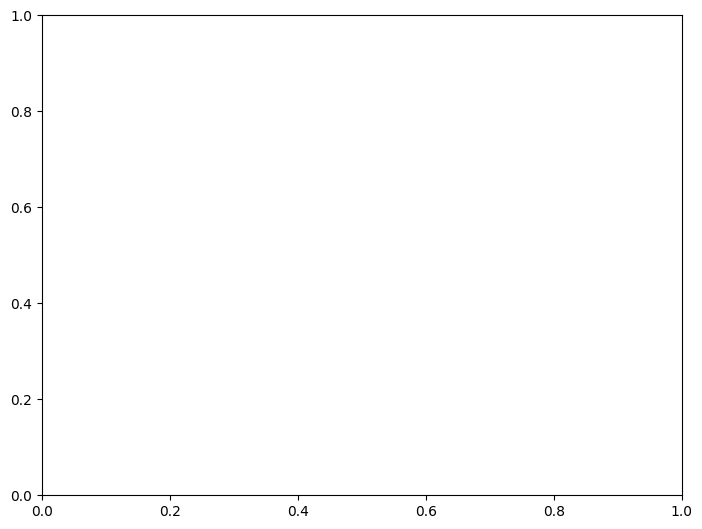

In [54]:
#!pip install causal-learn
from causallearn.search.ConstraintBased.PC import pc

for key in names_datasets_train.keys():
    dataset = names_datasets_train[key]
    #display(dataset.values)
    cg = pc(dataset.values)
    print(cg.G.graph) #adjacency_matrix cg.G.graph
    nx.draw(cg.G)
    print("************")
    print(key)
    print(y_train[key])

    g = nx.DiGraph(y_train[key])
    nx.draw(g, with_labels=True)
    break


In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=11,
    n_jobs=-1,
    class_weight="balanced"
)
display(model)

cv = GroupKFold(n_splits=4)
results = cross_val_score(
    model,
    X_train_feat,
    y_train_feat,
    groups=group_train,
    cv=cv,
    verbose=True,
    scoring="balanced_accuracy"
)

print(f"multiclass balanced accuracy: mean={results.mean()}")

RandomForestClassifier(class_weight='balanced', max_depth=11, n_jobs=-1)

multiclass balanced accuracy: mean=0.3898723900349404


In [ ]:
!pip install xgboost

   ---------------------------------------- 0.0/124.9 MB ? eta -:--:--
    --------------------------------------- 1.8/124.9 MB 11.2 MB/s eta 0:00:12
   - -------------------------------------- 4.2/124.9 MB 11.0 MB/s eta 0:00:12
   -- ------------------------------------- 6.8/124.9 MB 11.3 MB/s eta 0:00:11
   --- ------------------------------------ 9.4/124.9 MB 11.7 MB/s eta 0:00:10
   --- ------------------------------------ 12.1/124.9 MB 12.0 MB/s eta 0:00:10
   ---- ----------------------------------- 14.9/124.9 MB 12.0 MB/s eta 0:00:10
   ----- ---------------------------------- 17.6/124.9 MB 12.0 MB/s eta 0:00:09
   ------ --------------------------------- 20.2/124.9 MB 12.1 MB/s eta 0:00:09
   ------- -------------------------------- 22.8/124.9 MB 12.1 MB/s eta 0:00:09
   -------- ------------------------------- 25.4/124.9 MB 12.2 MB/s eta 0:00:09
   -------- ------------------------------- 28.0/124.9 MB 12.2 MB/s eta 0:00:08
   --------- ------------------------------ 30.7/124.

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import GroupKFold, cross_val_score

X_train_feat.columns = X_train_feat.columns.astype(str).str.replace('[\[\]<]', '', regex=True)

model = XGBClassifier(
    n_estimators=100,
    max_depth=9,
    subsample=0.8,
    n_jobs=-1,
    objective="multi:softmax",
    eval_metric="logloss"
)
display(model)

cv = GroupKFold(n_splits=4)
results = cross_val_score(
    model,
    X_train_feat,
    y_train_feat,
    groups=group_train,
    cv=cv,
    verbose=True,
    scoring="balanced_accuracy"
)

print(f"multiclass balanced accuracy: mean={results.mean()}")

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=9,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, objective='multi:softmax', ...)

multiclass balanced accuracy: mean=0.3515966187852148


In [1]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [7, 9, 11, 13],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0]
}

print(y_train_feat)

grid_search = GridSearchCV(
    estimator=XGBClassifier(objective="multi:softmax", eval_metric="mlogloss", n_jobs=-1), # tree_method="gpu_hist"),
    param_grid=param_grid,
    scoring='balanced_accuracy',
    cv=3,
    verbose=3,
)


grid_search.fit(X_train_feat, y_train_feat)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best balanced accuracy: {grid_search.best_score_}")

#Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 100, 'subsample': 0.8}

NameError: name 'y_train_feat' is not defined

In [ ]:
best_model = grid_search.best_estimator_

cv = GroupKFold(n_splits=4)
results = cross_val_score(
    best_model,
    X_train_feat,
    y_train_feat,
    groups=group_train,
    cv=cv,
    verbose=True,
    scoring="balanced_accuracy"
)

print(f"Multiclass balanced accuracy: mean={results.mean()}")

Multiclass balanced accuracy: mean=0.3570836586169281


### MLP

In [ ]:
!pip install tensorflow

   ---------------------------------------- 0.0/385.0 MB ? eta -:--:--
   ---------------------------------------- 1.3/385.0 MB 8.4 MB/s eta 0:00:46
   ---------------------------------------- 4.5/385.0 MB 11.7 MB/s eta 0:00:33
    --------------------------------------- 7.3/385.0 MB 11.9 MB/s eta 0:00:32
   - -------------------------------------- 10.0/385.0 MB 11.9 MB/s eta 0:00:32
   - -------------------------------------- 12.6/385.0 MB 11.9 MB/s eta 0:00:32
   - -------------------------------------- 14.9/385.0 MB 12.0 MB/s eta 0:00:31
   - -------------------------------------- 17.6/385.0 MB 12.2 MB/s eta 0:00:31
   -- ------------------------------------- 20.2/385.0 MB 12.1 MB/s eta 0:00:31
   -- ------------------------------------- 22.8/385.0 MB 12.2 MB/s eta 0:00:30
   -- ------------------------------------- 25.4/385.0 MB 12.2 MB/s eta 0:00:30
   -- ------------------------------------- 28.0/385.0 MB 12.3 MB/s eta 0:00:30
   --- ------------------------------------ 30.9/385.

  You can safely remove it manually.
  You can safely remove it manually.


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

def create_mlp(input_dim):
    model = Sequential()
    model.add(Dense(64, input_dim=input_dim, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(32, activation='relu'))
    model.add(Dropout(0.5))
    model.add(Dense(3, activation='softmax'))  # Assuming 3 classes for multi-class classification
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import LabelEncoder
import numpy as np

# Encode the target labels
le = LabelEncoder()
#y_train_encoded = le.fit_transform(y_train_feat)

# Define the GroupKFold cross-validator
group_kfold = GroupKFold(n_splits=4)

# Convert the data to numpy arrays
X_train_np = X_train_feat.to_numpy()
y_train_np = np.array(y_train_feat) 
groups_np = group_train.to_numpy()

In [ ]:
#!pip install scikeras
!pip install tensorflow-intel

#from scikeras.wrappers import KerasClassifier

In [1]:
!pip uninstall tensorflow numpy
#!pip install tensorflow-intel numpy

^C


In [2]:
import tensorflow as tf
import numpy as np

data = np.array([[0.1, 0.2, 0.3], [0.8, 0.9, 1.0], [1.5, 1.6, 1.7], ])
layer = tf.keras.layers.Normalization()
layer.adapt(data)
normalized_data = layer(data)

In [3]:
import numpy as np
import tensorflow as tf
print(tf.__version__)
print(np.__version__)

from tensorflow.keras.layers import Normalization
import keras


data = np.array([[0.1, 0.2, 0.3], [0.8, 0.9, 1.0], [1.5, 1.6, 1.7],])
#layer = preprocessing.Normalization()
layer = keras.layers.Normalization(axis=-1)
layer.adapt(data)
#layer.adapt(data)
normalized_data = layer(data)
print(normalized_data)

2.17.0
1.26.4
tf.Tensor(
[[-1.2247449 -1.2247449 -1.2247449]
 [ 0.         0.         0.       ]
 [ 1.2247449  1.224745   1.224745 ]], shape=(3, 3), dtype=float32)


In [ ]:
#from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import cross_val_score

model = create_mlp(input_dim=X_train_feat.shape[1])

print(type(X_train_np))
print(type(y_train_np))

history = model.fit(X_train_np, y_train_np, epochs=10, batch_size=32, validation_split=0.2, verbose=3)

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Test accuracy: {test_accuracy}")

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


ValueError: object __array__ method not producing an array

In [ ]:
#X_y_group_train["dataset"].value_counts()

#X_val_split.shape #107183, 13
print(y_val_pred[0:8]) #numpy.ndarray
print(y_val_split[0:8].values) #pd.series

#X_y_group_train[["dataset", "y"]].head(16)
sum = 0 
for aKey in X_train.keys():
    sum += len(X_train[aKey].columns) - 2

print(sum) # 142910 size of X_train_feat
#display(X_train['00000'].head())


[4 1 4 6 5 1 5 5]
[5 6 1 1 7 1 1 0]
142910


In [ ]:
print(len(X_train))
print(len(X_train_feat))
print(len(X_y_group_train))

23500
142910
142910


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit

model = RandomForestClassifier(
    n_estimators=100,
    max_depth=11,
    n_jobs=-1,
    class_weight="balanced"
)
display(model)

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=64)
train_indices, val_indices = next(gss.split(X_train_feat, groups=group_train))
X_train_feat = X_y_group_train.drop(["variable", "dataset", "label", "y"], axis="columns")


X_train_split = X_train_feat.loc[train_indices]
y_train_split = y_train_feat.loc[train_indices]
X_val_split = X_train_feat.loc[val_indices]
y_val_split = y_train_feat.loc[val_indices]

model.fit(X_train_split, y_train_split)

y_val_pred = model.predict(X_val_split)

accuracy = accuracy_score(y_val_split, y_val_pred)
balanced_accuracy = balanced_accuracy_score(y_val_split, y_val_pred)

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Balanced Accuracy: {balanced_accuracy:.2%}")
#PC, Lingam, FCI

RandomForestClassifier(class_weight='balanced', max_depth=11, n_jobs=-1)

Validation Accuracy: 47.29%
Validation Balanced Accuracy: 39.00%


In [ ]:
filtered_df = X_y_group_val[X_y_group_val["dataset"] == "01909"]
result_df = filtered_df[["dataset", "correct", "y", "prediction"]]
print(result_df)
#print("*********")
#print(X_y_group_train[X_y_group_train["dataset"] == "00000"])
#print("*********")
#display(X_train['00000'].head())

     dataset  correct  y  prediction
5668   01909     True  6           6
5669   01909     True  1           1
5670   01909     True  6           6
5671   01909     True  6           6
5672   01909     True  1           1
5673   01909     True  6           6
5674   01909     True  6           6
5675   01909     True  6           6


In [ ]:

train_dataset_counts = X_y_group_train.iloc[val_indices]["dataset"].value_counts()

# Determine correct and incorrect predictions
correct_predictions = y_val_split == y_val_pred
X_y_group_val = X_y_group_train.iloc[val_indices].copy()
X_y_group_val["correct"] = correct_predictions
X_y_group_val["prediction"] = y_val_pred

filtered_df = X_y_group_val[X_y_group_val["dataset"] == "00007"]
#print("Filtered DataFrame for dataset '00007':")
#print(filtered_df)

# Group by dataset size and count correct and incorrect predictions
val_dataset_counts = X_y_group_val.groupby("dataset").size()
correct_counts = X_y_group_val.groupby("dataset")["correct"].sum()
incorrect_counts = val_dataset_counts - correct_counts

# Combine the results into a DataFrame
results = pd.DataFrame({
    "size": val_dataset_counts,
    "correct": correct_counts,
    "incorrect": incorrect_counts
})

print(f"Validation Balanced Accuracy: {balanced_accuracy:.2%}")
print("Distribution of count of correct and incorrect predictions in the validation set:")
print(results)


Validation Balanced Accuracy: 39.00%
Distribution of count of correct and incorrect predictions in the validation set:
         size  correct  incorrect
dataset                          
00007       8        3          5
00011       6        4          2
00016       4        2          2
00028       5        2          3
00030       8        6          2
...       ...      ...        ...
46953       8        1          7
46957       6        1          5
46962       7        7          0
46967       8        6          2
46969       8        5          3

[5875 rows x 3 columns]


In [ ]:
correct_predictions = y_val_split == y_val_pred
X_y_group_val = X_y_group_train.iloc[val_indices].copy()
X_y_group_val["correct"] = correct_predictions

accuracy_per_dataset = X_y_group_val.groupby("dataset").apply(
    lambda df: pd.Series({
        "accuracy": df["correct"].sum() / len(df),
        "denominator": len(df)
    })
)

print("Accuracy and denominator for each dataset in the validation set:")
print(accuracy_per_dataset)

Accuracy and denominator for each dataset in the validation set:
         accuracy  denominator
dataset                       
00007    0.375000          8.0
00011    0.666667          6.0
00016    0.500000          4.0
00028    0.400000          5.0
00030    0.750000          8.0
...           ...          ...
46953    0.125000          8.0
46957    0.166667          6.0
46962    1.000000          7.0
46967    0.750000          8.0
46969    0.625000          8.0

[5875 rows x 2 columns]


C:\Users\em11877\AppData\Local\Temp\ipykernel_28444\175086817.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  accuracy_per_dataset = X_y_group_val.groupby("dataset").apply(


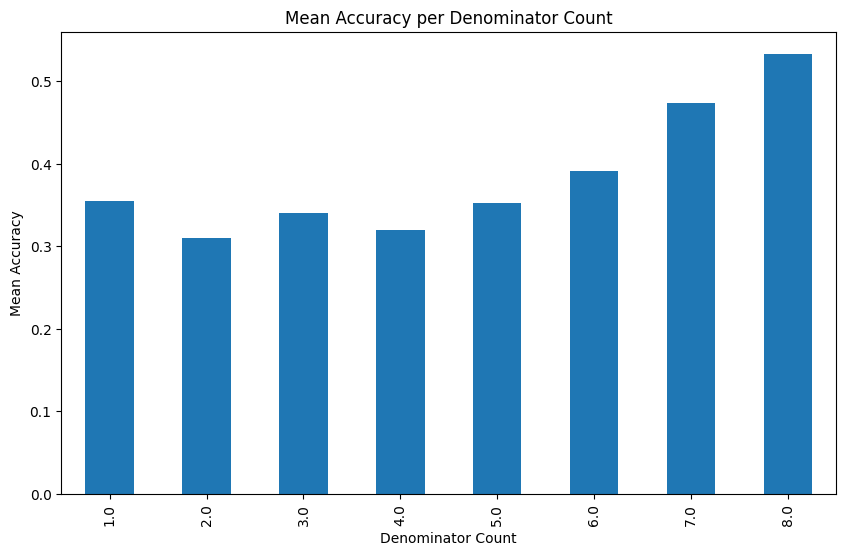

In [ ]:
mean_accuracy_per_denominator = accuracy_per_dataset.groupby("denominator")["accuracy"].mean()

plt.figure(figsize=(10, 6))
mean_accuracy_per_denominator.plot(kind='bar')
plt.xlabel('Denominator Count')
plt.ylabel('Mean Accuracy')
plt.title('Mean Accuracy per Denominator Count')
plt.show()

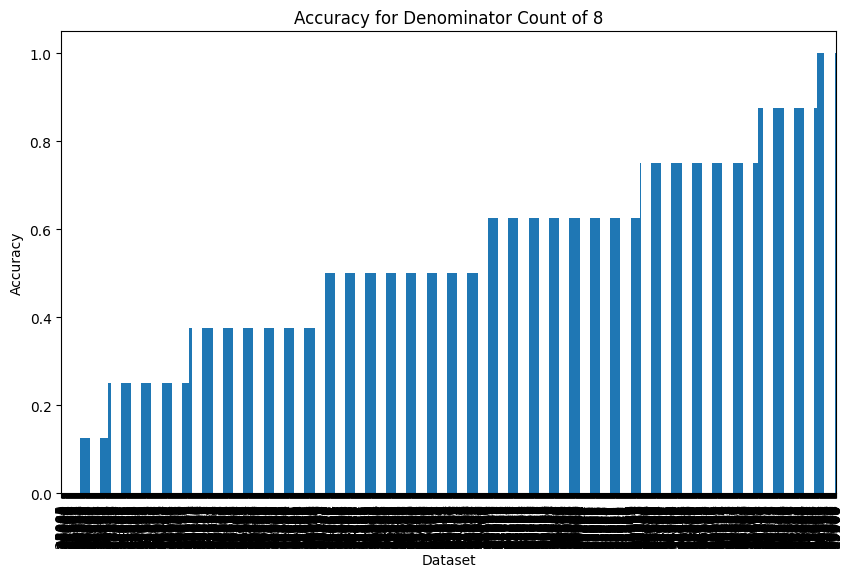

In [ ]:
accuracy_for_denominator_8 = accuracy_per_dataset[accuracy_per_dataset["denominator"] == 8]
accuracy_for_denominator_8 = accuracy_for_denominator_8.sort_values(by="accuracy")

# Plot the accuracy for denominator count of 8
plt.figure(figsize=(10, 6))
accuracy_for_denominator_8["accuracy"].plot(kind='bar')
plt.xlabel('Dataset')
plt.ylabel('Accuracy')
plt.title('Accuracy for Denominator Count of 8')
plt.show()

In [ ]:
high_accuracy_datasets = accuracy_per_dataset[
    (accuracy_per_dataset["accuracy"] > 0.90) & (accuracy_per_dataset["denominator"] >= 8)
]

# Display the filtered DataFrame
print("Datasets with more than 90% accuracy and a denominator of 8 or more:")
print(len(high_accuracy_datasets))
print(high_accuracy_datasets)

Datasets with more than 90% accuracy and a denominator of 8 or more:
56
         accuracy  denominator
dataset                       
01909         1.0          8.0
03540         1.0          8.0
04363         1.0          8.0
04960         1.0          8.0
07697         1.0          8.0
08006         1.0          8.0
08785         1.0          8.0
09578         1.0          8.0
09748         1.0          8.0
09762         1.0          8.0
10866         1.0          8.0
11414         1.0          8.0
13632         1.0          8.0
15112         1.0          8.0
15588         1.0          8.0
15666         1.0          8.0
15808         1.0          8.0
15978         1.0          8.0
17239         1.0          8.0
21484         1.0          8.0
22553         1.0          8.0
22904         1.0          8.0
23910         1.0          8.0
24861         1.0          8.0
24909         1.0          8.0
25033         1.0          8.0
26448         1.0          8.0
26658         1.0          8.

In [ ]:
print(f"Total data size: {len(X_y_group_train)}")
print(f"Training set size: {len(X_train_split)}")
print(f"Validation set size: {len(X_val_split)}")

print(f"Validation set percentage of total data: {len(X_val_split) / len(X_y_group_train):.2%}")
print(f"Validation set percentage of training data: {len(X_val_split) / (len(X_train_split) + len(X_val_split)):.2%}")

Total data size: 142910
Training set size: 321547
Validation set size: 107183
Validation set percentage of total data: 75.00%
Validation set percentage of training data: 25.00%


In [ ]:
print( len(X_train) )  #142910
print( len(X_y_group_train) ) #142910
print( len(X_y_group_val) )  #107183
print( len(X_train_split) ) #321547
print(len(X_train_split) + len(X_val_split) ) #428730

print("*********")
print(len(X_train_split)  / (len(X_train_split) + len(X_val_split)))
print(len(X_y_group_val)  / (len(X_train_split) + len(X_val_split)))
print("*********")

print( len(X_y_group_val) / len(X_y_group_train) ) #107183 142910

print( len(X_y_group_val) / len(X_train) ) 

print( len(val_indices) / (len(train_indices) + len(val_indices) ) ) 
print( len(train_indices) / (len(train_indices) + len(val_indices) ) )


142910
142910
107183
321547
428730
*********
0.7499988337648403
0.25000116623515967
*********
0.750003498705479
0.750003498705479
0.25000116623515967
0.7499988337648403


## CrunchDAO Code Interface

[Submitting to the CrunchDAO platform requires 2 functions, `train` and `infer`.](https://docs.crunchdao.com/competitions/code-interface) Any line that is not in a function or is not an import will be commented when the notebook is processed.

The content of the function is the same as the example, but the train must save the model to be read in infer. This allows for more predictable behavior if the program is restarted without training.

In [ ]:
# Uncomment what you need!
def train(
    X_train: typing.Dict[str, pd.DataFrame],
    y_train: typing.Dict[str, pd.DataFrame],
    # number_of_features: int,
    model_directory_path: str,
    # id_column_name: str,
    # prediction_column_name: str,
    # has_gpu: bool,
) -> None:
    # 1) Create the variable embedding:
    X_y_group_train_pathname = "/tmp/X_y_group_train.parquet"
    try:
        print(f"Loading {X_y_group_train_pathname}")
        X_y_group_train = pd.read_parquet(X_y_group_train_pathname)
    except FileNotFoundError:
        print("Creating X_y_group_train")
        names_datasets_train = X_train
        names_graphs_train = y_train
        X_y_group_train = create_all_columns(
            {
                pearson_correlation: names_datasets_train,
                ttest: names_datasets_train,
                mutual_information: names_datasets_train,  # comment this line to greatly reduce computation
                label: names_graphs_train,
            },
            n_jobs=-1,
        )

        # 2) Massage X_y_group_train to prepare what is needed by the model:
        print("Adding numeric labels y") # sklearn wants numeric labels
        le = LabelEncoder()
        le.classes_ = np.array([
            'Cause of X', 'Consequence of X', 'Confounder', 'Collider',
            'Mediator', 'Independent', 'Cause of Y', 'Consequence of Y',
        ])
        X_y_group_train["y"] = le.transform(X_y_group_train["label"])

        # reordering columns:
        X_y_group_train = X_y_group_train[["dataset", "variable"] + X_y_group_train.columns.drop(["dataset", "variable", "label", "y"]).tolist() + ["label", "y"]]
        display(X_y_group_train)

        print("Saving X_y_group_train")
        os.makedirs(os.path.dirname(X_y_group_train_pathname), exist_ok=True)
        X_y_group_train.to_parquet(X_y_group_train_pathname)

    print("Extracting X_train, y_train, and group")
    X_train = X_y_group_train.drop(["variable", "dataset", "label", "y"], axis="columns")
    y_train = X_y_group_train["y"]
    group_train = X_y_group_train["dataset"]

    # Model:
    model = RandomForestClassifier(n_estimators=100, max_depth=11, n_jobs=-1, class_weight="balanced")
    model.fit(X_train, y_train)

    joblib.dump(
        model,
        os.path.join(model_directory_path, "model.joblib")
    )

In [ ]:
def create_submission(X_y_pred_test):
    """
    From the predicted test set, for each dataset, take predicted
    classes of all variables, create the adjacency matrix, then create
    the submission in the requested format.
    """

    submission = {}
    for name, prediction in tqdm(X_y_pred_test.groupby("dataset"), delay=10):
        variables_labels = prediction[["variable", "label_predicted"]].set_index("variable")
        variables = variables_labels.index.tolist()
        variables_all = ["X", "Y"] + variables

        adjacency_matrix = pd.DataFrame(index=variables_all, columns=variables_all)
        adjacency_matrix.index.name = "parent"
        adjacency_matrix[:] = 0
        adjacency_matrix.loc["X", "Y"] = 1

        for v in variables:
            l = variables_labels.loc[v].item()
            if l == "Cause of X":
                adjacency_matrix.loc[v, "X"] = 1
            elif l == "Cause of Y":
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Consequence of X":
                adjacency_matrix.loc["X", v] = 1
            elif l == "Consequence of Y":
                adjacency_matrix.loc["Y", v] = 1
            elif l == "Confounder":
                adjacency_matrix.loc[v, "X"] = 1
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Collider":
                adjacency_matrix.loc["X", v] = 1
                adjacency_matrix.loc["Y", v] = 1
            elif l == "Mediator":
                adjacency_matrix.loc["X", v] = 1
                adjacency_matrix.loc[v, "Y"] = 1
            elif l == "Confounder":
                pass

        for i in variables_all:
            for j in variables_all:
                submission[f'{name}_{i}_{j}'] = int(adjacency_matrix.loc[i, j])

    return submission


# Uncomment what you need!
def infer(
    X_test: typing.Dict[str, pd.DataFrame],
    # number_of_features: int,
    model_directory_path: str,
    id_column_name: str,
    prediction_column_name: str,
    # has_gpu: bool,
    # has_trained: bool,
) -> pd.DataFrame:
    model = joblib.load(os.path.join(model_directory_path, "model.joblib"))

    names_datasets_test = X_test
    X_group_test = create_all_columns(
        {
            pearson_correlation: names_datasets_test,
            ttest: names_datasets_test,
            mutual_information: names_datasets_test,  # comment this line to greatly reduce computation
        },
        n_jobs=-1,
    )

    X_test = X_group_test.drop(columns=["dataset", "variable"])
    y_predicted = model.predict(X_test)
    X_y_pred_test = X_group_test
    X_y_pred_test["y_predicted"] = y_predicted

    le = LabelEncoder()
    le.classes_ = np.array([
        'Cause of X', 'Consequence of X', 'Confounder', 'Collider',
        'Mediator', 'Independent', 'Cause of Y', 'Consequence of Y',
    ])

    X_y_pred_test["label_predicted"] = le.inverse_transform(y_predicted)

    submission = create_submission(X_y_pred_test)

    return pd.DataFrame(
        submission.items(),
        columns=[
            id_column_name,
            prediction_column_name
        ]
    )

### Local Testing

Before submitting your notebook, please make sure that it works locally so that you do not waste compute time. The `crunch.test()` will execute your code with the same logic as it will in the cloud environment.

In [ ]:
crunch.test(
    no_determinism_check=True
)

print("Download this notebook and submit it to the platform: https://hub.crunchdao.com/competitions/causality-discovery/submit/via/notebook")